# A Proximity-Based Early Warning System for Gentrification in California
**UE24CS352A – Machine Learning Mini-Project**

**Problem.** Predict, for each California Census tract, whether housing costs rise over 2012–2016 (`housing_gentrification_label`), using only information available *before* 2012: 2010→2011 changes in census variables, the tract's own pre-2012 change, and *proximity* features describing neighbouring tracts (spatial lag and local Moran's I).

**Approach.** Binary classification with Logistic Regression (L1), Random Forest, XGBoost, an XGBoost regressor on the underlying cost change, and a rank-averaged ensemble. All model selection uses repeated stratified cross-validation on train+validation; the test set is used **once** at the end. Every number shown below is computed by this notebook – nothing is typed in by hand.

**Reference.** Pattabi, *A Proximity-Based Early Warning System for Gentrification in California*, Stanford CS229 (2018).

## 1. Setup

In [8]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import rankdata
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)

DATA_PATH = os.environ.get("DATA_PATH", "../data/final_dataset.csv")
QUICK = os.environ.get("QUICK", "0") == "1"      # True = fast pass (fewer repeats/trees)
SEED = 42
N_REPEATS = 1 if QUICK else 2                    # CV repeats
N_TREES = 150 if QUICK else 300                  # Random Forest trees
N_TUNE_ITER = 6 if QUICK else 20                 # XGBoost random-search iterations

TARGET, RESPONSE = "housing_gentrification_label", "housing_cost_response"
SPATIAL = ["spatial_lag_housing_pre2012", "local_morans_I_housing_pre2012",
           "spatial_lag_income_pre2012", "local_morans_I_income_pre2012"]
PRE = ["pre_housing_change", "pre_income_change"]

## 2. Load data and sanity checks

In [9]:
df = pd.read_csv(r"C:\Users\User\OneDrive\Documents\SEM 5\ML_mini_pro\data\final_dataset.csv")
print("Shape:", df.shape)
print("\nSplit sizes:\n", df["split"].value_counts().to_string())

# --- ID consistency: tract_id must agree with county_fips / tract_code ---
county_from_id = (df["tract_id"] // 1_000_000) % 1000
tract_from_id = df["tract_id"] % 1_000_000
id_county = (county_from_id == df["county_fips"]).mean()
id_tract = (tract_from_id == df["tract_code"]).mean()
print(f"\ntract_id agrees with county_fips: {id_county:.1%} | with tract_code: {id_tract:.1%}")
if min(id_county, id_tract) < 0.99:
    print("WARNING: ID columns disagree. Check how the CSV was merged (must be joined on a key, "
          "never by row position). IDs are not used as features, but misaligned rows would ruin any model.")

print("\nMissing values (columns with any):")
print(df.isna().sum()[lambda s: s > 0].to_string())
print("\nLabel == (cost change > 0): %.1f%% agreement" % (((df[RESPONSE] > 0).astype(int) == df[TARGET]).mean() * 100))

Shape: (7965, 167)

Split sizes:
 split
train         7168
test           399
validation     398

tract_id agrees with county_fips: 11.1% | with tract_code: 0.0%

Missing values (columns with any):
pre_housing_change    546
pre_income_change       7

Label == (cost change > 0): 100.0% agreement


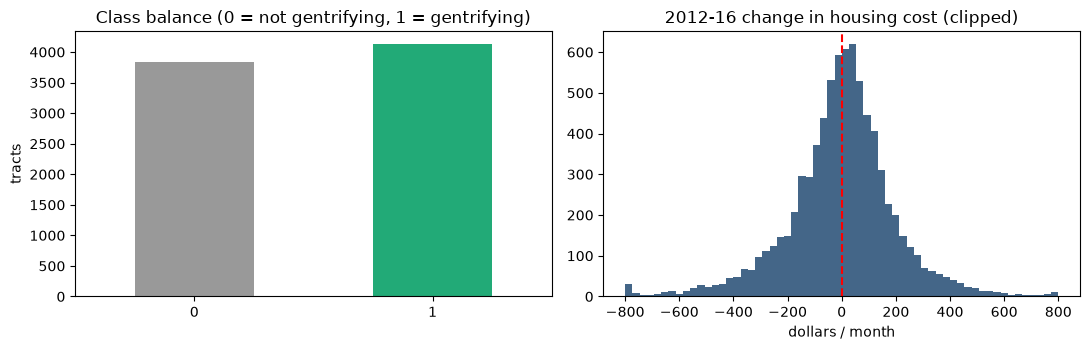

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df[TARGET].value_counts().sort_index().plot.bar(ax=ax[0], color=["#999", "#2a7"], rot=0)
ax[0].set(title="Class balance (0 = not gentrifying, 1 = gentrifying)", xlabel="", ylabel="tracts")
ax[1].hist(df[RESPONSE].clip(-800, 800), bins=60, color="#468")
ax[1].axvline(0, color="r", ls="--")
ax[1].set(title="2012-16 change in housing cost (clipped)", xlabel="dollars / month")
plt.tight_layout(); plt.show()

The label is essentially the **sign of a noisy cost change**, so tracts near zero change are close to coin flips. This puts a ceiling on achievable accuracy, which we quantify in section 8.

## 3. Features
No leakage: only 2010→2011 and pre-2012 quantities are used. Columns dropped: IDs, `split`, and everything derived from the 2012–2016 outcome.

Compared with a naive set, we **keep** `pre_housing_change` / `pre_income_change` (the tract's own pre-2012 change; NaNs are median-imputed and flagged) and add two engineered contrasts between a tract and its neighbours. Four feature sets are compared:

In [11]:
delta_cols = [c for c in df.columns if c.startswith("delta_")]
X_all = df[delta_cols + SPATIAL + PRE].copy()
X_all["pre_housing_missing"] = df["pre_housing_change"].isna().astype(int)
X_all["pre_income_missing"] = df["pre_income_change"].isna().astype(int)
X_all["housing_vs_neighbors"] = df["pre_housing_change"] - df["spatial_lag_housing_pre2012"]
X_all["income_vs_neighbors"] = df["pre_income_change"] - df["spatial_lag_income_pre2012"]

PRE_F = PRE + ["pre_housing_missing", "pre_income_missing"]
ENG = ["housing_vs_neighbors", "income_vs_neighbors"]
FEATURE_SETS = {
    "A_baseline (census deltas + proximity)": delta_cols + SPATIAL,
    "B  + own pre-2012 change":               delta_cols + SPATIAL + PRE_F,
    "C  + neighbour contrasts":               delta_cols + SPATIAL + PRE_F + ENG,
    "D_core (no census deltas)":              SPATIAL + PRE_F + ENG,
}
for k, v in FEATURE_SETS.items():
    print(f"{k:<42} {len(v):>4} features")

dev = df["split"].isin(["train", "validation"]).values
test = (df["split"] == "test").values
X_dev, y_dev, r_dev = X_all[dev].reset_index(drop=True), df.loc[dev, TARGET].values, df.loc[dev, RESPONSE].values
X_te, y_te = X_all[test].reset_index(drop=True), df.loc[test, TARGET].values
print(f"\nDevelopment rows (train+validation): {len(y_dev)} | Test rows: {len(y_te)}")
print(f"Majority-class accuracy -> dev {max(y_dev.mean(), 1-y_dev.mean()):.4f} | test {max(y_te.mean(), 1-y_te.mean()):.4f}")

A_baseline (census deltas + proximity)      154 features
B  + own pre-2012 change                    158 features
C  + neighbour contrasts                    160 features
D_core (no census deltas)                    10 features

Development rows (train+validation): 7566 | Test rows: 399
Majority-class accuracy -> dev 0.5206 | test 0.5163


## 4. Models
With ~150 noisy features and ~7.5k rows, strong regularisation matters (the reference report's grid search chose large XGBoost λ, small L1 `C`, few features per split). Models:
- **logreg_L1** – quantile-transformed inputs, L1 penalty
- **rf** – Random Forest, small `max_features`, `min_samples_leaf=15`
- **xgb** – shallow, heavily regularised XGBoost classifier
- **xgb_reg** – XGBoost *regressor* on the (winsorised) cost change; uses the magnitude of the change, not just its sign
- **ensemble** – average of the models' rank-normalised scores

Scores are compared by **ROC-AUC**. For accuracy/precision/recall each model labels the top *p*% of scores as positive, where *p* is the training positive rate – this avoids the "trigger-happy" over-prediction of the positive class.

In [12]:
PARAMS = {"C": 0.02,
          "xgb": dict(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8,
                      colsample_bytree=0.4, min_child_weight=10, reg_lambda=25)}

def _imp(): return SimpleImputer(strategy="median")

def make_classifiers(n_feat, seed):
    mf = 18 if n_feat >= 60 else max(2, n_feat // 2)
    return {
        "logreg_L1": Pipeline([("imp", _imp()),
                               ("qt", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=seed)),
                               ("m", LogisticRegression(penalty="l1", solver="liblinear", C=PARAMS["C"], max_iter=500))]),
        "rf": Pipeline([("imp", _imp()),
                        ("m", RandomForestClassifier(n_estimators=N_TREES, max_features=mf, min_samples_leaf=15,
                                                     n_jobs=-1, random_state=seed))]),
        "xgb": Pipeline([("imp", _imp()),
                         ("m", XGBClassifier(**PARAMS["xgb"], tree_method="hist", n_jobs=-1,
                                             random_state=seed, eval_metric="logloss"))]),
    }

def make_regressor(seed):
    return Pipeline([("imp", _imp()),
                     ("m", XGBRegressor(**PARAMS["xgb"], tree_method="hist", n_jobs=-1, random_state=seed))])

def fit_scores(Xtr, ytr, rtr, Xva, seed):
    """Fit all models on the training rows; return a score vector per model for Xva."""
    s = {}
    for name, mdl in make_classifiers(Xtr.shape[1], seed).items():
        mdl.fit(Xtr, ytr); s[name] = mdl.predict_proba(Xva)[:, 1]
    lo, hi = np.percentile(rtr, [1, 99])
    reg = make_regressor(seed).fit(Xtr, np.clip(rtr, lo, hi))
    s["xgb_reg"] = reg.predict(Xva)
    s["ensemble"] = np.mean([rankdata(v) / len(v) for v in s.values()], axis=0)
    return s

def to_labels(score, pos_rate):
    return (score >= np.quantile(score, 1 - pos_rate)).astype(int)

## 5. Cross-validated comparison of feature sets

In [13]:
def cv_eval(cols, drop_below=0, n_splits=5, seed=SEED):
    """Repeated stratified CV on train+val. Rows with |cost change| < drop_below are removed
    from TRAINING folds only; evaluation always uses every row of the held-out fold."""
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=N_REPEATS, random_state=seed)
    rows, oof = [], {}
    for i, (tr, va) in enumerate(rskf.split(X_dev, y_dev)):
        if drop_below > 0:
            tr = tr[np.abs(r_dev[tr]) >= drop_below]
        sc = fit_scores(X_dev.iloc[tr][cols], y_dev[tr], r_dev[tr], X_dev.iloc[va][cols], seed + i)
        for name, s in sc.items():
            pred = to_labels(s, y_dev[tr].mean())
            rows.append(dict(fold=i, model=name, auc=roc_auc_score(y_dev[va], s),
                             acc=accuracy_score(y_dev[va], pred)))
            oof.setdefault(name, np.full((N_REPEATS, len(y_dev)), np.nan))[i // n_splits, va] = s
    return pd.DataFrame(rows), oof

def summarise(res):
    g = res.groupby("model")
    return pd.DataFrame({"AUC": g.auc.mean(), "AUC_sd": g.auc.std(),
                         "Acc": g.acc.mean(), "Acc_sd": g.acc.std()}).sort_values("AUC", ascending=False).round(4)

exp1, summ1 = {}, {}
for name, cols in FEATURE_SETS.items():
    exp1[name], _ = cv_eval(cols)
    summ1[name] = summarise(exp1[name])
    print(f"\n{name}"); display(summ1[name])

fs_table = pd.DataFrame({k: v["AUC"] for k, v in summ1.items()}).T
display(Markdown("**Mean CV ROC-AUC by feature set and model**")); display(fs_table.round(4))
best_fs = fs_table.max(axis=1).idxmax()
print("Best feature set by CV AUC:", best_fs)


A_baseline (census deltas + proximity)


,AUC,AUC_sd,Acc,Acc_sd
model,,,,
xgb_reg,0.5540,0.0129,0.5374,0.0118
ensemble,0.5514,0.0107,0.5379,0.0100
rf,0.5496,0.0097,0.5338,0.0077
xgb,0.5393,0.0110,0.5252,0.0070
logreg_L1,0.5391,0.0135,0.5245,0.0101



B  + own pre-2012 change


,AUC,AUC_sd,Acc,Acc_sd
model,,,,
xgb_reg,0.5680,0.0118,0.5486,0.0082
ensemble,0.5637,0.0090,0.5431,0.0051
rf,0.5581,0.0123,0.5385,0.0070
xgb,0.5544,0.0078,0.5375,0.0079
logreg_L1,0.5413,0.0122,0.5275,0.0110



C  + neighbour contrasts


,AUC,AUC_sd,Acc,Acc_sd
model,,,,
xgb_reg,0.5702,0.0106,0.5529,0.0063
ensemble,0.5663,0.0085,0.5505,0.0088
rf,0.5657,0.0112,0.5461,0.0128
xgb,0.5557,0.0094,0.5391,0.0082
logreg_L1,0.5408,0.0119,0.5287,0.0096



D_core (no census deltas)


,AUC,AUC_sd,Acc,Acc_sd
model,,,,
xgb_reg,0.5815,0.0144,0.5563,0.0129
ensemble,0.5800,0.0138,0.5539,0.0114
xgb,0.5797,0.0146,0.5555,0.0119
rf,0.5710,0.0130,0.5456,0.0110
logreg_L1,0.5480,0.0120,0.5340,0.0102


**Mean CV ROC-AUC by feature set and model**

model,ensemble,logreg_L1,rf,xgb,xgb_reg
A_baseline (census deltas + proximity),0.5514,0.5391,0.5496,0.5393,0.5540
B + own pre-2012 change,0.5637,0.5413,0.5581,0.5544,0.5680
C + neighbour contrasts,0.5663,0.5408,0.5657,0.5557,0.5702
D_core (no census deltas),0.5800,0.5480,0.5710,0.5797,0.5815


Best feature set by CV AUC: D_core (no census deltas)


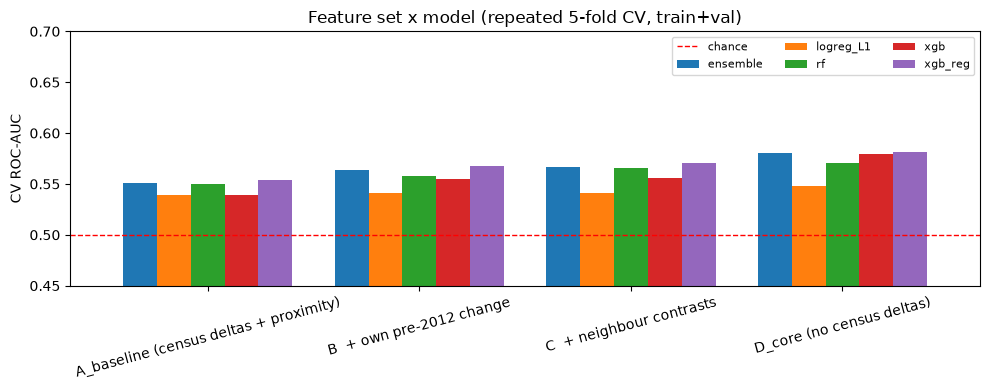

In [14]:
ax = fs_table.plot.bar(figsize=(10, 4), rot=15, width=0.8)
ax.axhline(0.5, color="r", ls="--", lw=1, label="chance")
ax.set(ylabel="CV ROC-AUC", title="Feature set x model (repeated 5-fold CV, train+val)")
ax.set_ylim(0.45, max(0.7, fs_table.values.max() + 0.03)); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig("fig_featureset_cv.png", dpi=200); plt.show()

## 6. Tuning and label-noise filtering
Light tuning of the logistic-regression `C` and the XGBoost hyper-parameters (CV on the training data only). Then we test whether **removing near-zero-change tracts from the training folds** (not from evaluation) helps, since those labels are essentially random.

In [15]:
cols_best = FEATURE_SETS[best_fs]
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)

# --- L1 logistic regression: choose C ---
c_scores = {}
for C in [0.005, 0.01, 0.02, 0.05, 0.1, 0.3]:
    PARAMS["C"] = C
    m = make_classifiers(len(cols_best), SEED)["logreg_L1"]
    c_scores[C] = cross_val_score(m, X_dev[cols_best], y_dev, cv=skf, scoring="roc_auc").mean()
PARAMS["C"] = max(c_scores, key=c_scores.get)
print("L1 C scores:", {k: round(v, 4) for k, v in c_scores.items()}, "-> C =", PARAMS["C"])

# --- XGBoost: randomised search (strong-regularisation ranges) ---
space = {"m__n_estimators": [150, 250, 400], "m__max_depth": [2, 3, 4],
         "m__learning_rate": [0.02, 0.03, 0.05, 0.08], "m__subsample": [0.6, 0.8, 1.0],
         "m__colsample_bytree": [0.2, 0.4, 0.6], "m__min_child_weight": [5, 10, 20, 40],
         "m__reg_lambda": [10, 25, 50, 100]}
xgb_pipe = Pipeline([("imp", _imp()), ("m", XGBClassifier(tree_method="hist", n_jobs=-1,
                                                        random_state=SEED, eval_metric="logloss"))])
search = RandomizedSearchCV(xgb_pipe, space, n_iter=N_TUNE_ITER, scoring="roc_auc", cv=skf,
                            random_state=SEED, n_jobs=1).fit(X_dev[cols_best], y_dev)
PARAMS["xgb"] = {k.replace("m__", ""): v for k, v in search.best_params_.items()}
print("XGBoost best params:", PARAMS["xgb"], "| search CV AUC: %.4f" % search.best_score_)

L1 C scores: {0.005: np.float64(0.5224), 0.01: np.float64(0.5439), 0.02: np.float64(0.5465), 0.05: np.float64(0.5479), 0.1: np.float64(0.5477), 0.3: np.float64(0.547)} -> C = 0.05
XGBoost best params: {'subsample': 0.6, 'reg_lambda': 25, 'n_estimators': 250, 'min_child_weight': 20, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.4} | search CV AUC: 0.5816


In [16]:
exp2, summ2, oof2, rows = {}, {}, {}, []
for thr in [0, 25, 50, 100]:
    exp2[thr], oof2[thr] = cv_eval(cols_best, drop_below=thr)
    summ2[thr] = summarise(exp2[thr])
    for m, r in summ2[thr].iterrows():
        rows.append(dict(drop_below=thr, model=m, AUC=r.AUC, AUC_sd=r.AUC_sd, Acc=r.Acc, Acc_sd=r.Acc_sd))
tune_table = pd.DataFrame(rows)
display(Markdown(f"**Mean CV ROC-AUC, tuned models on `{best_fs}`** (rows = minimum |cost change| kept in training)"))
display(tune_table.pivot(index="drop_below", columns="model", values="AUC").round(4))

best = tune_table.sort_values("AUC", ascending=False).iloc[0]
BEST_THR, BEST_MODEL = int(best.drop_below), best.model
print(f"Selected by CV -> model: {BEST_MODEL} | training filter: |change| >= {BEST_THR} | CV AUC {best.AUC:.4f}")
tune_table.to_csv("results_cv.csv", index=False)

**Mean CV ROC-AUC, tuned models on `D_core (no census deltas)`** (rows = minimum |cost change| kept in training)

model,ensemble,logreg_L1,rf,xgb,xgb_reg
drop_below,,,,,
0,0.5801,0.5483,0.5710,0.5794,0.5817
25,0.5809,0.5483,0.5730,0.5819,0.5830
50,0.5812,0.5482,0.5762,0.5815,0.5826
100,0.5827,0.5491,0.5806,0.5849,0.5823


Selected by CV -> model: xgb | training filter: |change| >= 100 | CV AUC 0.5849


## 7. Proximity-feature ablation (paired, identical folds)

In [17]:
prox_like = set(SPATIAL + ENG)
cols_wo = [c for c in cols_best if c not in prox_like]
res_wo, _ = cv_eval(cols_wo, drop_below=BEST_THR)
a = exp2[BEST_THR].query("model == @BEST_MODEL").sort_values("fold").auc.values
b = res_wo.query("model == @BEST_MODEL").sort_values("fold").auc.values
diff = a - b
abl_mean, abl_se = diff.mean(), diff.std(ddof=1) / np.sqrt(len(diff))
display(pd.DataFrame({"with proximity features": [a.mean()], "without": [b.mean()],
                      "paired diff": [abl_mean], "std. error": [abl_se]}, index=[BEST_MODEL]).round(4))
abl_sig = abl_mean > 2 * abl_se
print("Proximity features give a clear gain (diff > 2 SE):", abl_sig)

,with proximity features,without,paired diff,std. error
xgb,0.5849,0.5598,0.0251,0.005


Proximity features give a clear gain (diff > 2 SE): True


## 8. How much of the error is label noise?

,AUC,n
size of |cost change|,,
smallest 25%,0.5500,1917.0
25-50%,0.5403,1866.0
50-75%,0.6027,1900.0
largest 25%,0.6549,1883.0


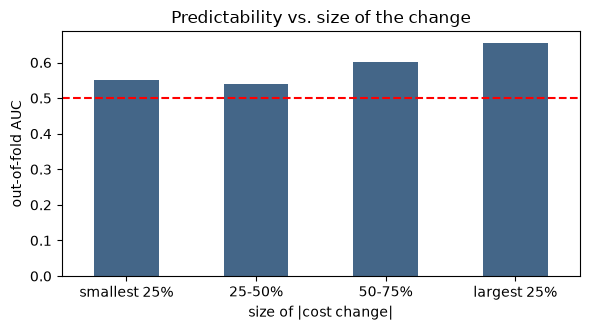

In [18]:
p_oof = np.nanmean(oof2[BEST_THR][BEST_MODEL], axis=0)
mag = np.abs(r_dev)
bins = pd.qcut(mag, 4, labels=["smallest 25%", "25-50%", "50-75%", "largest 25%"])
noise_tbl = pd.DataFrame({b_: {"AUC": roc_auc_score(y_dev[bins == b_], p_oof[bins == b_]),
                               "n": int((bins == b_).sum())} for b_ in bins.categories}).T
noise_tbl.index.name = "size of |cost change|"
display(noise_tbl.round(4))
ax = noise_tbl["AUC"].plot.bar(rot=0, figsize=(6, 3.4), color="#468")
ax.axhline(0.5, color="r", ls="--"); ax.set(ylabel="out-of-fold AUC", title="Predictability vs. size of the change")
plt.tight_layout(); plt.savefig("fig_noise_ceiling.png", dpi=200); plt.show()

If AUC rises with the size of the change, the weak overall score is mainly a **label-noise ceiling** (small changes are unpredictable), not a pipeline bug.

## 9. Final evaluation on the untouched test set
Everything above used train+validation only. The chosen configuration is refit on all development rows and evaluated on the test set **once**, with bootstrap 95% confidence intervals.

In [19]:
keep = np.abs(r_dev) >= BEST_THR if BEST_THR > 0 else np.ones(len(y_dev), bool)
sc_te = fit_scores(X_dev.loc[keep, cols_best], y_dev[keep], r_dev[keep], X_te[cols_best], SEED)
pos_rate = y_dev[keep].mean()

def boot_ci(y, s, n=1000, seed=0):
    rng, A, K = np.random.default_rng(seed), [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        A.append(roc_auc_score(y[i], s[i])); K.append(accuracy_score(y[i], to_labels(s[i], pos_rate)))
    return np.percentile(A, [2.5, 97.5]), np.percentile(K, [2.5, 97.5])

rows = []
for name, s in sc_te.items():
    pred = to_labels(s, pos_rate)
    rows.append(dict(model=name, AUC=roc_auc_score(y_te, s), Accuracy=accuracy_score(y_te, pred),
                     Precision=precision_score(y_te, pred), Recall=recall_score(y_te, pred), F1=f1_score(y_te, pred)))
test_table = pd.DataFrame(rows).set_index("model").round(4)
display(Markdown("**All models on the test set** (selection was made by CV, not by this table)"))
display(test_table)

s_fin = sc_te[BEST_MODEL]; pred_fin = to_labels(s_fin, pos_rate)
auc_te, acc_te = roc_auc_score(y_te, s_fin), accuracy_score(y_te, pred_fin)
auc_ci, acc_ci = boot_ci(y_te, s_fin)
base_acc = max(y_te.mean(), 1 - y_te.mean())
print(f"SELECTED MODEL: {BEST_MODEL}  ({best_fs}, training filter >= {BEST_THR})")
print(f"Test ROC-AUC  {auc_te:.4f}   95% CI [{auc_ci[0]:.3f}, {auc_ci[1]:.3f}]")
print(f"Test accuracy {acc_te:.4f}   95% CI [{acc_ci[0]:.3f}, {acc_ci[1]:.3f}]   (majority baseline {base_acc:.4f})")

**All models on the test set** (selection was made by CV, not by this table)

,AUC,Accuracy,Precision,Recall,F1
model,,,,,
logreg_L1,0.5289,0.5113,0.4951,0.5233,0.5088
rf,0.6206,0.5865,0.5686,0.6010,0.5844
xgb,0.6391,0.6065,0.5882,0.6218,0.6045
xgb_reg,0.6313,0.6015,0.5833,0.6166,0.5995
ensemble,0.6196,0.5915,0.5735,0.6062,0.5894


SELECTED MODEL: xgb  (D_core (no census deltas), training filter >= 100)
Test ROC-AUC  0.6391   95% CI [0.589, 0.695]
Test accuracy 0.6065   95% CI [0.556, 0.649]   (majority baseline 0.5163)


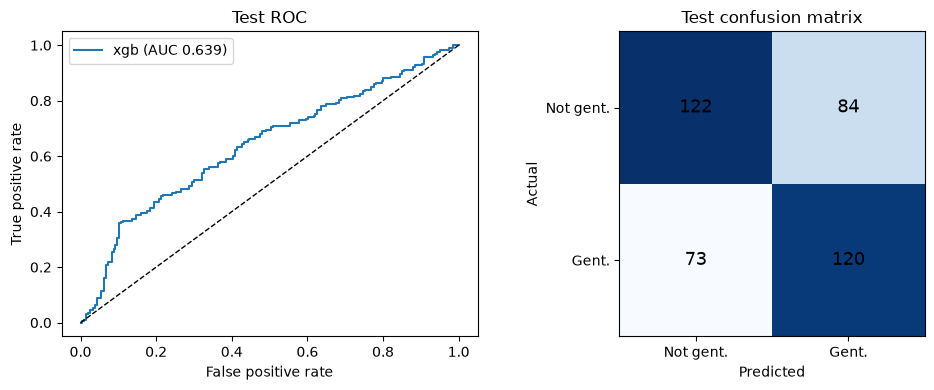

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
fpr, tpr, _ = roc_curve(y_te, s_fin)
ax[0].plot(fpr, tpr, label=f"{BEST_MODEL} (AUC {auc_te:.3f})"); ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="Test ROC"); ax[0].legend()
cm = confusion_matrix(y_te, pred_fin)
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax[1].text(j, i, v, ha="center", va="center", fontsize=13)
ax[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Not gent.", "Gent."], yticklabels=["Not gent.", "Gent."],
          xlabel="Predicted", ylabel="Actual", title="Test confusion matrix")
plt.tight_layout(); plt.savefig("fig_test_results.png", dpi=200); plt.show()

## 10. Which features matter? (XGBoost gain importance)

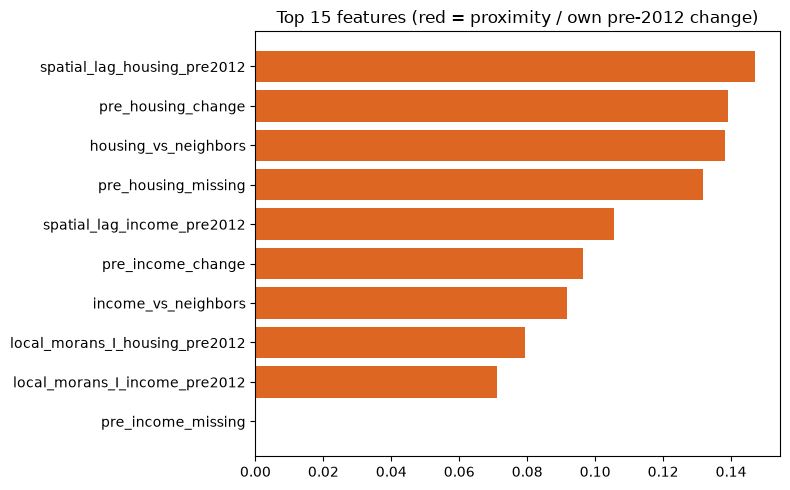

In [21]:
imp_model = make_classifiers(len(cols_best), SEED)["xgb"].fit(X_dev.loc[keep, cols_best], y_dev[keep])
imp = pd.Series(imp_model.named_steps["m"].feature_importances_, index=cols_best).sort_values(ascending=False)
top = imp.head(15)[::-1]
colors = ["#d62" if c in prox_like or c in PRE_F else "#468" for c in top.index]
plt.figure(figsize=(8, 5)); plt.barh(top.index, top.values, color=colors)
plt.title("Top 15 features (red = proximity / own pre-2012 change)"); plt.tight_layout()
plt.savefig("fig_feature_importance.png", dpi=200); plt.show()

## 11. Results summary (auto-generated from the run above)

In [22]:
cv_row = tune_table[(tune_table.drop_below == BEST_THR) & (tune_table.model == BEST_MODEL)].iloc[0]
verdict = ("The 95% CI of the test AUC excludes 0.5, so the model carries a statistically detectable signal."
           if auc_ci[0] > 0.5 else
           "The 95% CI of the test AUC includes 0.5, so on this test set the model cannot be distinguished from chance.")
prox_txt = ("removing the proximity/neighbour features lowers CV AUC by %.4f (SE %.4f), a clear contribution."
            if abl_sig else
            "removing the proximity/neighbour features changes CV AUC by %.4f (SE %.4f), which is not clearly different from zero.") % (abl_mean, abl_se)
display(Markdown(f"""
| Item | Value |
|---|---|
| Rows (dev / test) | {len(y_dev)} / {len(y_te)} |
| Features in final model | {len(cols_best)} (`{best_fs}`) |
| Selected model | `{BEST_MODEL}` (training filter: abs(change) >= {BEST_THR}) |
| CV ROC-AUC (train+val) | {cv_row.AUC:.4f} ± {cv_row.AUC_sd:.4f} |
| **Test ROC-AUC** | **{auc_te:.4f}** (95% CI {auc_ci[0]:.3f}–{auc_ci[1]:.3f}) |
| **Test accuracy** | **{acc_te:.4f}** (95% CI {acc_ci[0]:.3f}–{acc_ci[1]:.3f}); majority baseline {base_acc:.4f} |

{verdict}

Proximity ablation (paired CV, `{BEST_MODEL}`): {prox_txt}
"""))
with open("final_test_results.json", "w") as f:
    json.dump(dict(feature_set=best_fs, model=BEST_MODEL, drop_below=BEST_THR, cv_auc=float(cv_row.AUC),
                   test_auc=float(auc_te), test_acc=float(acc_te), test_auc_ci=auc_ci.tolist(),
                   test_acc_ci=acc_ci.tolist(), ablation_diff=float(abl_mean), ablation_se=float(abl_se),
                   params=PARAMS), f, indent=2, default=str)
test_table.to_csv("results_test.csv")


| Item | Value |
|---|---|
| Rows (dev / test) | 7566 / 399 |
| Features in final model | 10 (`D_core (no census deltas)`) |
| Selected model | `xgb` (training filter: abs(change) >= 100) |
| CV ROC-AUC (train+val) | 0.5849 ± 0.0169 |
| **Test ROC-AUC** | **0.6391** (95% CI 0.589–0.695) |
| **Test accuracy** | **0.6065** (95% CI 0.556–0.649); majority baseline 0.5163 |

The 95% CI of the test AUC excludes 0.5, so the model carries a statistically detectable signal.

Proximity ablation (paired CV, `xgb`): removing the proximity/neighbour features lowers CV AUC by 0.0251 (SE 0.0050), a clear contribution.


## 12. Limitations and conclusions
- **Label noise.** The target is the sign of a noisy median-cost change; tracts with small changes are close to unpredictable (section 8). This limits accuracy for any model.
- **Association, not causation.** Proximity features are predictive indicators, not proof that neighbours cause gentrification.
- **Single time window and geography.** Everything is one pivot year (2012) in one state; temporal or out-of-region validity is untested.
- **Selection optimism.** Feature-set choice and tuning use CV on the same development data, so CV scores are slightly optimistic; the test result (section 9) is the honest estimate, and its confidence interval shows how much a ~400-tract test set can resolve.
- **Future work.** Distance-weighted neighbourhoods instead of simple adjacency, richer pre-period levels (not only deltas), and spatial/temporal hold-out validation.

The conclusions that apply to *this* run are in the auto-generated summary above; quote only those numbers in the report and slides.